# Forecasting Sri Lanka's Air Quality with Ensemble Learning

**Question:** can we forecast tomorrow's air quality (US AQI) for every part of Sri Lanka, and which
kind of ensemble does it best: **bagging, boosting or stacking**? Can **hybrid** models
(Random Forest combined with ARIMA, a neural network, or boosting) do even better?

**About the dataset**

| Item | Details |
|:---|:---|
| Source | [dataset-sri-lanka-air-quality](https://github.com/th33k/dataset-sri-lanka-air-quality) (CC BY 4.0) |
| Origin | Copernicus Atmosphere Monitoring Service (CAMS), through the Open-Meteo API |
| Coverage | All 339 Divisional Secretariat Divisions (DSDs), 25 districts |
| Period | 1 January 2023 to 22 November 2026 |
| Frequency | One row per DSD per day, updated daily by a GitHub Action |
| Variables | US AQI, PM2.5, PM10, NO2, SO2, O3, CO, aerosol optical depth, dust, UV index |

CAMS values are model estimates on a ~45 km grid, not ground-station readings. 22 November 2026 is
the latest complete day when this notebook was run; running it later includes newer days.

**Plan**
1. Load and check daily air quality data for all 339 Divisional Secretariat Divisions (DSDs)
2. Explore it: trends, monsoon seasons, pollutants
3. Build features and split the data by date
4. Train baselines, then bagging, boosting and stacking models
5. Compare Random Forest with XGBoost, LightGBM and CatBoost
6. Try hybrids: RF + ARIMA, RF + ANN, RF + boosting
7. Compare everything and draw conclusions

The notebook runs top to bottom in Google Colab or locally in about 10 minutes.

## 0. Setup
Colab already has most libraries; CatBoost is installed if missing.

In [1]:
try:
    import catboost
except ImportError:
    %pip install -q catboost

In [2]:
import warnings
warnings.filterwarnings('ignore')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (BaggingRegressor, RandomForestRegressor, ExtraTreesRegressor,
                              AdaBoostRegressor, StackingRegressor)
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, TimeSeriesSplit, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from statsmodels.tsa.arima.model import ARIMA

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})

## 1. The data

The data comes from my dataset repository
[dataset-sri-lanka-air-quality](https://github.com/th33k/dataset-sri-lanka-air-quality), which
collects daily air quality for every DSD in Sri Lanka from 2023 to yesterday and updates itself
every day. The values come from the **Copernicus Atmosphere Monitoring Service (CAMS)** through
the Open-Meteo API.

Two things to know about this data:

* **CAMS is a model, not a ground sensor.** It estimates air quality on a grid of roughly 45 km
  squares. Sri Lanka has very few public monitoring stations, so this is the only source that
  covers the whole island every day.
* **Neighbouring DSDs often share one grid square**, so they have exactly the same values. The 339
  DSDs reduce to a few dozen distinct series, which I call **zones**. I train on zones so each real
  series counts once, then every DSD gets its zone's forecast.

The zone file (one row per zone per day) is built from the dataset by `src/prepare_data.py` in the
project repository. It is loaded here straight from GitHub, so nothing has to be uploaded to Colab.

In [ ]:
REPO = 'https://raw.githubusercontent.com/th33k/sri-lanka-air-quality-forecast/main/data/'

def load(name):
    # Use the local copy when running inside the project folder, otherwise download from GitHub
    from pathlib import Path
    local = Path('../data') / name
    return pd.read_csv(local if local.exists() else REPO + name)

df = load('zone_daily.csv.gz')
dsds = load('dsd_zones.csv')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['zone', 'date']).reset_index(drop=True)

print(f"{len(df):,} rows | {df.zone.nunique()} zones covering {len(dsds)} DSDs | "
      f"{df.date.min():%d %b %Y} to {df.date.max():%d %b %Y}")
df.head()

66,834 rows | 47 zones covering 339 DSDs | 01 Jan 2023 to 22 Nov 2026


,zone,date,pm25,pm25_max,pm10,no2,so2,o3,co,aod,dust,uv_max,aqi,aqi_max,lat,lon
0,1,2023-01-01,30.68,44.5,45.32,22.18,6.40,51.00,633.08,0.22,0.38,8.65,88.04,94.0,6.822,79.986
1,1,2023-01-02,44.07,65.9,65.38,25.11,8.25,76.25,764.04,0.39,0.62,8.30,101.38,119.0,6.822,79.986
2,1,2023-01-03,32.74,62.9,49.21,20.39,6.23,58.21,623.88,0.29,0.50,8.65,115.92,126.0,6.822,79.986
3,1,2023-01-04,37.67,61.0,56.72,25.73,7.17,53.92,747.25,0.30,1.00,8.85,94.75,104.0,6.822,79.986
4,1,2023-01-05,37.43,57.7,55.54,25.60,6.63,67.00,824.54,0.26,0.00,7.95,110.25,112.0,6.822,79.986


What the columns mean (daily values for one zone):

| Column | Meaning |
|:---|:---|
| `aqi`, `aqi_max` | US Air Quality Index, daily mean and maximum (the target) |
| `pm25`, `pm25_max`, `pm10` | fine and coarse particulate matter (µg/m³) |
| `no2`, `so2`, `o3`, `co` | nitrogen dioxide, sulphur dioxide, ozone, carbon monoxide (µg/m³) |
| `aod`, `dust` | aerosol optical depth and dust |
| `uv_max` | maximum UV index |
| `lat`, `lon` | centre of the zone |

### 1.1 Quick quality checks

In [4]:
all_days = pd.date_range(df.date.min(), df.date.max())
print('Duplicate zone-days:     ', df.duplicated(['zone', 'date']).sum())
print('Missing values:          ', df.isna().sum().sum())
print('Zones with missing days: ', (df.groupby('zone').date.nunique() != len(all_days)).sum())
print('AQI range:               ', df.aqi.min(), 'to', df.aqi.max())

Duplicate zone-days:      0
Missing values:           0
Zones with missing days:  0
AQI range:                14.79 to 171.12


No duplicates, no gaps and no missing values, so no cleaning is needed.

## 2. Exploring the data
### 2.1 How air quality changes over time

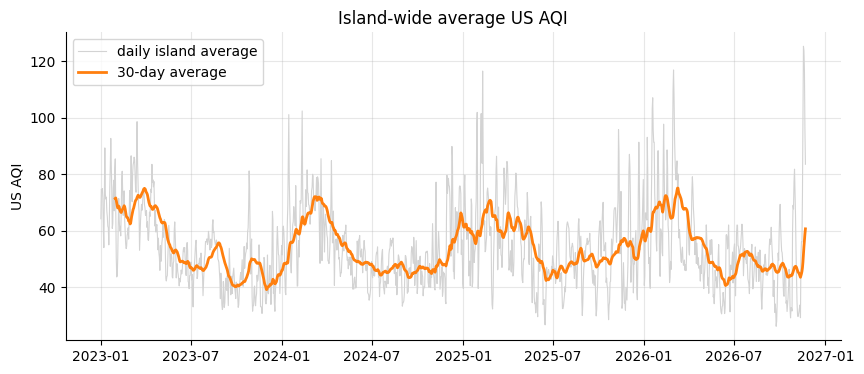

In [5]:
daily = df.groupby('date').aqi.mean()
plt.plot(daily, color='lightgray', lw=0.8, label='daily island average')
plt.plot(daily.rolling(30).mean(), color='tab:orange', lw=2, label='30-day average')
plt.title('Island-wide average US AQI'); plt.ylabel('US AQI'); plt.legend(); plt.show()

The same pattern repeats every year: air is worst around December to March and cleanest in the
middle of the year. That matches Sri Lanka's monsoons.

### 2.2 Monsoon seasons

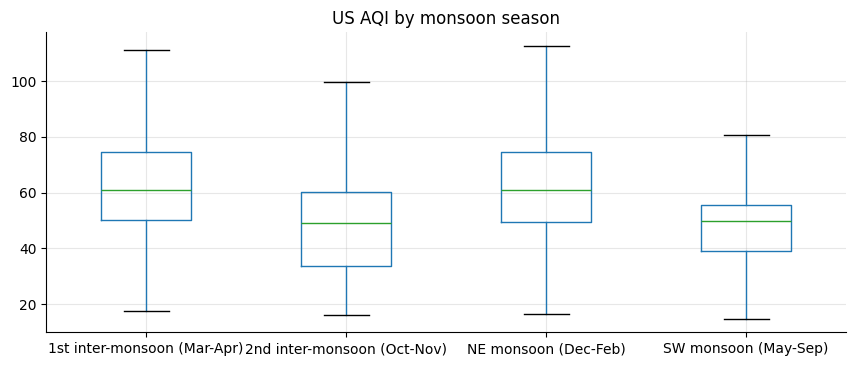

,aqi
season_name,
NE monsoon (Dec-Feb),62.7
1st inter-monsoon (Mar-Apr),63.2
SW monsoon (May-Sep),47.6
2nd inter-monsoon (Oct-Nov),49.6


In [6]:
def season(month):
    if month in (12, 1, 2): return 'NE monsoon (Dec-Feb)'
    if month in (3, 4):     return '1st inter-monsoon (Mar-Apr)'
    if month <= 9:          return 'SW monsoon (May-Sep)'
    return '2nd inter-monsoon (Oct-Nov)'

SEASON_ORDER = ['NE monsoon (Dec-Feb)', '1st inter-monsoon (Mar-Apr)', 'SW monsoon (May-Sep)', '2nd inter-monsoon (Oct-Nov)']
df['season_name'] = df.date.dt.month.map(season)
df.boxplot(column='aqi', by='season_name', showfliers=False, figsize=(10, 4))
plt.suptitle(''); plt.title('US AQI by monsoon season'); plt.xlabel(''); plt.show()
df.groupby('season_name').aqi.mean().reindex(SEASON_ORDER).round(1)

During the **North-East monsoon** winds blow from India and carry pollution over the island, so
AQI is highest. During the **South-West monsoon** the wind comes from the open ocean, so the air is
cleanest. Season will be a useful feature.

### 2.3 Which areas are worst?

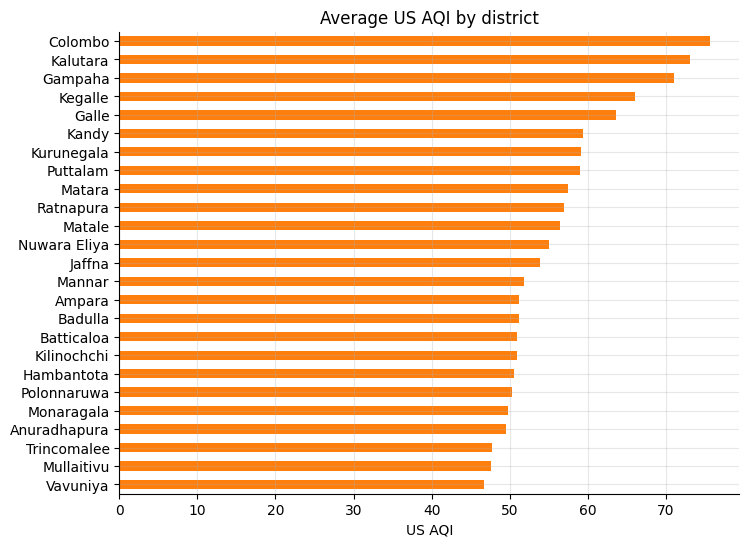

In [7]:
zone_mean = df.groupby('zone').aqi.mean()
by_district = dsds.assign(aqi=dsds.zone.map(zone_mean)).groupby('district').aqi.mean().sort_values()
by_district.plot.barh(figsize=(8, 6), color='tab:orange')
plt.title('Average US AQI by district'); plt.xlabel('US AQI'); plt.ylabel(''); plt.show()

The west and south (Colombo, Kalutara, Galle) are worst; the east is cleanest.

### 2.4 Which pollutants drive AQI?

In [8]:
df[['pm25', 'pm10', 'no2', 'so2', 'o3', 'co', 'aod', 'dust', 'uv_max']].corrwith(df.aqi).sort_values(ascending=False).round(2)

,0
pm25,0.92
pm10,0.86
aod,0.66
o3,0.61
co,0.54
no2,0.40
so2,0.36
dust,0.08
uv_max,0.03


AQI follows PM2.5 and PM10 almost exactly, because in Sri Lanka particulate matter is nearly
always the pollutant that sets the index.

### 2.5 Does today tell us about tomorrow?

In [9]:
pd.Series({f'{k} day(s) apart': daily.autocorr(k) for k in (1, 2, 3, 7, 30)}).round(3)

,0
1 day(s) apart,0.857
2 day(s) apart,0.652
3 day(s) apart,0.521
7 day(s) apart,0.281
30 day(s) apart,0.263


Today's AQI is very strongly correlated with tomorrow's (above 0.9). So the simple guess
"tomorrow = today" will already be good, and every model must beat it to be worth using.

## 3. Features and target

For each zone and day $t$ I use only information known at the end of that day:

* **Today's values**: AQI, PM2.5, PM10, gases, dust, UV
* **Recent history**: AQI 1, 2, 3 and 7 days ago, PM2.5 yesterday, 3- and 7-day averages, 7-day variability
* **Calendar**: day of week, month (as sine and cosine so December sits next to January), monsoon
  season, Sinhala and Tamil New Year week
* **Location**: latitude and longitude of the zone

**Target**: the zone's AQI on the next day ($t+1$).

In [10]:
def make_features(df):
    df = df.copy()
    g = df.groupby('zone')
    for k in (1, 2, 3, 7):
        df[f'aqi_lag{k}'] = g.aqi.shift(k)
    df['pm25_lag1'] = g.pm25.shift(1)
    df['aqi_mean3'] = g.aqi.transform(lambda s: s.rolling(3).mean())
    df['aqi_mean7'] = g.aqi.transform(lambda s: s.rolling(7).mean())
    df['aqi_std7'] = g.aqi.transform(lambda s: s.rolling(7).std())
    df['dow'] = df.date.dt.dayofweek
    df['month_sin'] = np.sin(2 * np.pi * df.date.dt.month / 12)
    df['month_cos'] = np.cos(2 * np.pi * df.date.dt.month / 12)
    df['season'] = df.season_name.map({s: i for i, s in enumerate(SEASON_ORDER)})
    df['new_year_week'] = ((df.date.dt.month == 4) & df.date.dt.day.between(10, 17)).astype(int)
    df['target'] = g.aqi.shift(-1)       # tomorrow's AQI
    df['target2'] = g.aqi.shift(-2)      # AQI two days ahead (used in section 9)
    return df.dropna(subset=['aqi_lag7', 'aqi_std7'])

FEATURES = ['aqi', 'aqi_max', 'pm25', 'pm25_max', 'pm10', 'no2', 'so2', 'o3', 'co', 'aod', 'dust', 'uv_max',
            'aqi_lag1', 'aqi_lag2', 'aqi_lag3', 'aqi_lag7', 'pm25_lag1', 'aqi_mean3', 'aqi_mean7', 'aqi_std7',
            'dow', 'month_sin', 'month_cos', 'season', 'new_year_week', 'lat', 'lon']
data = make_features(df)
print(len(FEATURES), 'features')

27 features


### 3.1 Train/test split by date

With time series the split must follow time. A random split would let the model "see the future":
it could train on Wednesday and be tested on Tuesday. So:

* the **first 70% of days** are for training
* the **last 30% of days** are the test set, used only once at the end
* the last training day is dropped, because its target (the next day) is already in the test period

In [11]:
data = data.dropna(subset=['target'])
days = np.sort(data.date.unique())
cutoff = days[int(len(days) * 0.7)]

train = data[data.date < cutoff - pd.Timedelta(days=1)].sort_values(['date', 'zone'])
test = data[data.date >= cutoff].sort_values(['date', 'zone'])
X_train, y_train = train[FEATURES], train.target
X_test, y_test = test[FEATURES], test.target

print(f"Train: {train.date.min():%d %b %Y} to {train.date.max():%d %b %Y}  ({len(train):,} rows)")
print(f"Test:  {test.date.min():%d %b %Y} to {test.date.max():%d %b %Y}  ({len(test):,} rows)")

Train: 08 Jan 2023 to 21 Sep 2025  (46,436 rows)
Test:  23 Sep 2025 to 21 Nov 2026  (19,975 rows)


### 3.2 How models are scored

* **RMSE**: typical error in AQI points, punishing big misses more (main metric, lower is better)
* **MAE**: average error in AQI points (lower is better)
* **R²**: share of the day-to-day variation explained (1 is perfect)

In [12]:
results, predictions = [], {}

def evaluate(name, family, pred, seconds=None):
    pred = np.clip(pred, 0, None)            # AQI cannot be negative
    predictions[name] = pred
    results.append({'model': name, 'family': family,
                    'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
                    'MAE': mean_absolute_error(y_test, pred),
                    'R2': r2_score(y_test, pred),
                    'train_seconds': seconds})
    return results[-1]

def fit_and_evaluate(name, family, model):
    start = time.time()
    model.fit(X_train, y_train)
    return model, evaluate(name, family, model.predict(X_test), round(time.time() - start, 1))

def table(family=None):
    t = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
    return (t[t.family == family] if family else t).round(3)

## 4. Baselines

Simple methods every model has to beat:
* **Persistence**: tomorrow = today
* **Ridge regression**: a straight-line model using all features
* **Decision tree**: a single tree, the building block of the ensembles

In [13]:
evaluate('Persistence (tomorrow = today)', 'Baseline', X_test.aqi.values)
fit_and_evaluate('Ridge regression', 'Baseline', make_pipeline(StandardScaler(), Ridge()))
fit_and_evaluate('Decision tree', 'Baseline', DecisionTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=SEED))
table('Baseline')

,model,family,RMSE,MAE,R2,train_seconds
0,Decision tree,Baseline,7.258,5.132,0.879,0.7
1,Ridge regression,Baseline,7.422,5.630,0.874,0.1
2,Persistence (tomorrow = today),Baseline,11.287,8.173,0.709,NaN


## 5. Bagging

**Idea:** train many trees, each on a random sample of the training data, and average their
answers. One deep tree overfits; the average of many different trees is much more stable.

* **Bagged trees**: plain bagging of decision trees
* **Random Forest (RF)**: bagging, plus each split only looks at a random subset of features
* **Extra Trees**: like RF, but split points are also chosen at random

The settings below come from a time-series cross-validated search on the training data (an
example of that search is in section 6.1).

In [14]:
bagging = BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=3), n_estimators=80, max_samples=0.5,
                           random_state=SEED, n_jobs=-1)
rf = RandomForestRegressor(n_estimators=200, max_depth=16, min_samples_leaf=5, max_features=0.8,
                           random_state=SEED, n_jobs=-1)
et = ExtraTreesRegressor(n_estimators=200, max_depth=16, min_samples_leaf=5, max_features=0.9,
                         random_state=SEED, n_jobs=-1)

bagging, _ = fit_and_evaluate('Bagged trees', 'Bagging', bagging)
rf, _ = fit_and_evaluate('Random Forest', 'Bagging', rf)
et, _ = fit_and_evaluate('Extra Trees', 'Bagging', et)
table('Bagging')

,model,family,RMSE,MAE,R2,train_seconds
0,Random Forest,Bagging,6.281,4.397,0.910,163.1
1,Bagged trees,Bagging,6.320,4.435,0.909,67.5
2,Extra Trees,Bagging,6.421,4.487,0.906,28.2


## 6. Boosting

**Idea:** build trees one after another. Each new tree focuses on the mistakes of the trees before
it, so the model keeps correcting itself.

* **AdaBoost**: gives more weight to the examples it got most wrong
* **XGBoost**, **LightGBM**, **CatBoost**: gradient boosting, each new tree predicts the remaining
  error. They differ in how they grow trees and handle regularisation.

In [15]:
ada = AdaBoostRegressor(n_estimators=100, learning_rate=0.05, random_state=SEED)
xgb = XGBRegressor(n_estimators=200, max_depth=5, learning_rate=0.08, subsample=0.9, colsample_bytree=0.85,
                   min_child_weight=8, random_state=SEED, n_jobs=-1)
lgbm = LGBMRegressor(n_estimators=200, num_leaves=46, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9,
                     min_child_samples=26, random_state=SEED, n_jobs=-1, verbose=-1)
cat = CatBoostRegressor(iterations=250, depth=5, learning_rate=0.1, l2_leaf_reg=10, random_state=SEED, verbose=0)

ada, _ = fit_and_evaluate('AdaBoost', 'Boosting', ada)
xgb, _ = fit_and_evaluate('XGBoost', 'Boosting', xgb)
lgbm, _ = fit_and_evaluate('LightGBM', 'Boosting', lgbm)
cat, _ = fit_and_evaluate('CatBoost', 'Boosting', cat)
table('Boosting')

,model,family,RMSE,MAE,R2,train_seconds
2,LightGBM,Boosting,6.382,4.458,0.907,4.4
4,XGBoost,Boosting,6.487,4.518,0.904,2.3
5,CatBoost,Boosting,6.525,4.568,0.903,3.2
8,AdaBoost,Boosting,7.634,5.575,0.867,39.5


### 6.1 How the settings were chosen (example: LightGBM)

Hyperparameters are tuned only on the training data, with **time-series cross-validation**: each
fold trains on earlier days and validates on the days right after, so tuning never peeks ahead.

In [16]:
search = RandomizedSearchCV(
    LGBMRegressor(random_state=SEED, n_jobs=-1, verbose=-1),
    {'n_estimators': [100, 200, 300, 400], 'num_leaves': [15, 31, 46], 'learning_rate': [0.03, 0.05, 0.08, 0.12],
     'subsample': [0.7, 0.9, 1.0], 'colsample_bytree': [0.6, 0.8, 0.9], 'min_child_samples': [10, 26, 50]},
    n_iter=10, cv=TimeSeriesSplit(n_splits=4), scoring='neg_root_mean_squared_error', random_state=SEED)
search.fit(X_train, y_train)
print('Best settings:', search.best_params_)
print(f'Cross-validated RMSE: {-search.best_score_:.2f}')

Best settings: {'subsample': 0.9, 'num_leaves': 15, 'n_estimators': 200, 'min_child_samples': 26, 'learning_rate': 0.08, 'colsample_bytree': 0.9}
Cross-validated RMSE: 5.76


## 7. Stacking

**Idea:** instead of picking one model, let a simple **meta-model** learn how much to trust each
one. Random Forest, XGBoost, LightGBM and CatBoost each make predictions, and a Ridge regression
learns the best weights. The meta-model is trained on *out-of-fold* predictions (each base model
predicts data it was not trained on), so it learns honest weights.

In [17]:
stack = StackingRegressor(
    estimators=[('rf', rf), ('xgb', xgb), ('lgbm', lgbm), ('cat', cat)],
    final_estimator=RidgeCV(), cv=KFold(n_splits=5), n_jobs=-1)
stack, _ = fit_and_evaluate('Stacking (RF + XGB + LGBM + CatBoost)', 'Stacking', stack)
print('Weights learned by the meta-model:')
print(pd.Series(stack.final_estimator_.coef_, index=['RF', 'XGBoost', 'LightGBM', 'CatBoost']).round(3).to_string())
table('Stacking')

Weights learned by the meta-model:
RF          0.583
XGBoost     0.050
LightGBM    0.160
CatBoost    0.227


,model,family,RMSE,MAE,R2,train_seconds
0,Stacking (RF + XGB + LGBM + CatBoost),Stacking,6.235,4.366,0.911,893.0


## 8. Random Forest vs boosting: which is best?

A small RMSE gap could just be luck. To check, I **bootstrap the test days**: resample the test
days 1,000 times, recompute the RMSE difference each time, and look at the 95% range. If the
whole range is on one side of zero, the difference is real.

In [18]:
test_days = test.date.values
unique_days = np.unique(test_days)
rng = np.random.default_rng(SEED)
boot_days = [rng.choice(len(unique_days), len(unique_days)) for _ in range(1000)]

def daily_sq_error(name):
    return pd.Series((predictions[name] - y_test.values) ** 2).groupby(test_days).mean().values

def compare(a, b):
    # 95% interval for RMSE(a) - RMSE(b), resampling whole test days
    ea, eb = daily_sq_error(a), daily_sq_error(b)
    diffs = [np.sqrt(ea[i].mean()) - np.sqrt(eb[i].mean()) for i in boot_days]
    low, high = np.percentile(diffs, [2.5, 97.5])
    verdict = f'{a} better' if high < 0 else f'{b} better' if low > 0 else 'no clear difference'
    return {'model A': a, 'model B': b, 'RMSE A - B': np.sqrt(ea.mean()) - np.sqrt(eb.mean()),
            '95% low': low, '95% high': high, 'verdict': verdict}

rf_vs_boosting = pd.DataFrame([compare('Random Forest', m) for m in
                               ['XGBoost', 'LightGBM', 'CatBoost', 'AdaBoost', 'Stacking (RF + XGB + LGBM + CatBoost)']])
rf_vs_boosting.round(3)

,model A,model B,RMSE A - B,95% low,95% high,verdict
0,Random Forest,XGBoost,-0.206,-0.398,-0.056,Random Forest better
1,Random Forest,LightGBM,-0.101,-0.237,0.006,no clear difference
2,Random Forest,CatBoost,-0.244,-0.390,-0.124,Random Forest better
3,Random Forest,AdaBoost,-1.353,-1.543,-1.155,Random Forest better
4,Random Forest,Stacking (RF + XGB + LGBM + CatBoost),0.046,0.012,0.080,Stacking (RF + XGB + LGBM + CatBoost) better


## 9. Hybrid models

Each hybrid pairs Random Forest with a different kind of model.

| Hybrid | How it works |
|:---|:---|
| **RF + ARIMA (ARIMA as a feature)** | A classic time-series model (ARIMA) forecasts tomorrow for each zone; RF gets that forecast as an extra feature |
| **ARIMA + RF (RF fixes ARIMA's errors)** | ARIMA forecasts first, RF learns to correct its errors |
| **RF + ANN (average)** | Average of RF and a small neural network |
| **RF + ANN (stacked)** | A meta-model learns how to weight RF and the neural network |
| **RF + boosting (vote)** | Average of RF, XGBoost, LightGBM and CatBoost |
| **RF + LightGBM (LightGBM fixes RF's errors)** | LightGBM learns to correct RF's errors |

### 9.1 RF + ARIMA

ARIMA(2,0,1) is fitted per zone on the training days only. Then, for every day, it gives its
forecast for the next day using only data up to that day.

In [19]:
def arima_forecasts(df, cutoff):
    out = []
    for zone, g in df.groupby('zone'):
        y = g.aqi.values.astype(float)
        n_train = (g.date < cutoff).sum()
        fitted = ARIMA(y[:n_train], order=(2, 0, 1)).fit()    # learn the parameters on training days
        run = fitted.apply(y)                                  # run the same model over all days
        # fittedvalues[i] is the forecast for day i made on day i-1, so day t's forecast for t+1 is [t+1]
        next_day = np.append(run.fittedvalues[1:], run.forecast(1))
        out.append(pd.DataFrame({'zone': zone, 'date': g.date.values, 'arima': next_day}))
    return pd.concat(out)

arima = arima_forecasts(df, cutoff)
train_a = train.merge(arima, on=['zone', 'date'])
test_a = test.merge(arima, on=['zone', 'date'])
assert (test_a.date.values == test.date.values).all() and (test_a.zone.values == test.zone.values).all()

evaluate('ARIMA alone', 'Time series', test_a.arima.values)

rf_params = rf.get_params()
rf_arima = RandomForestRegressor(**rf_params).fit(train_a[FEATURES + ['arima']], train_a.target)
evaluate('RF + ARIMA (ARIMA as a feature)', 'Hybrid RF + ARIMA', rf_arima.predict(test_a[FEATURES + ['arima']]))

rf_on_resid = RandomForestRegressor(**rf_params).fit(train_a[FEATURES], train_a.target - train_a.arima)
evaluate('ARIMA + RF (RF fixes ARIMA errors)', 'Hybrid RF + ARIMA', test_a.arima.values + rf_on_resid.predict(test_a[FEATURES]))
table().query("family in ['Time series', 'Hybrid RF + ARIMA']")

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarnin

,model,family,RMSE,MAE,R2,train_seconds
1,RF + ARIMA (ARIMA as a feature),Hybrid RF + ARIMA,6.264,4.393,0.910,NaN
8,ARIMA + RF (RF fixes ARIMA errors),Hybrid RF + ARIMA,7.172,4.955,0.882,NaN
12,ARIMA alone,Time series,10.474,7.718,0.749,NaN


### 9.2 RF + ANN
The neural network is a small multi-layer perceptron (64 and 32 neurons) on standardised features, with early stopping to avoid overfitting.

In [20]:
ann = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True,
                                                   max_iter=300, random_state=SEED))
ann, _ = fit_and_evaluate('ANN alone', 'Component', ann)
evaluate('RF + ANN (average)', 'Hybrid RF + ANN', (predictions['Random Forest'] + predictions['ANN alone']) / 2)

rf_ann = StackingRegressor([('rf', RandomForestRegressor(**rf_params)), ('ann', ann)],
                           final_estimator=RidgeCV(), cv=KFold(n_splits=5), n_jobs=-1)
fit_and_evaluate('RF + ANN (stacked)', 'Hybrid RF + ANN', rf_ann)
table().query("family in ['Component', 'Hybrid RF + ANN']")

,model,family,RMSE,MAE,R2,train_seconds
0,RF + ANN (stacked),Hybrid RF + ANN,6.109,4.290,0.915,954.7
1,RF + ANN (average),Hybrid RF + ANN,6.138,4.334,0.914,NaN
9,ANN alone,Component,6.522,4.672,0.903,20.6


### 9.3 RF + boosting
For the residual version, RF's errors come from its *out-of-bag* predictions (each tree predicts the rows it never saw), so LightGBM learns from honest errors.

In [21]:
vote = np.mean([predictions[m] for m in ['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost']], axis=0)
evaluate('RF + boosting (vote)', 'Hybrid RF + boosting', vote)

rf_oob = RandomForestRegressor(**{**rf_params, 'oob_score': True}).fit(X_train, y_train)
lgbm_fix = LGBMRegressor(**lgbm.get_params()).fit(X_train, y_train - rf_oob.oob_prediction_)
evaluate('RF + LightGBM (LightGBM fixes RF errors)', 'Hybrid RF + boosting', rf_oob.predict(X_test) + lgbm_fix.predict(X_test))
table('Hybrid RF + boosting')

,model,family,RMSE,MAE,R2,train_seconds
3,RF + LightGBM (LightGBM fixes RF errors),Hybrid RF + boosting,6.253,4.346,0.911,NaN
7,RF + boosting (vote),Hybrid RF + boosting,6.325,4.422,0.908,NaN


### 9.4 Do the hybrids beat Random Forest alone?

In [22]:
so_far = table()
hybrid_names = so_far[so_far.family.str.startswith('Hybrid')].model
pd.DataFrame([compare(h, 'Random Forest') for h in hybrid_names]).round(3)

,model A,model B,RMSE A - B,95% low,95% high,verdict
0,RF + ANN (stacked),Random Forest,-0.172,-0.223,-0.123,RF + ANN (stacked) better
1,RF + ANN (average),Random Forest,-0.143,-0.226,-0.063,RF + ANN (average) better
2,RF + LightGBM (LightGBM fixes RF errors),Random Forest,-0.028,-0.119,0.085,no clear difference
3,RF + ARIMA (ARIMA as a feature),Random Forest,-0.017,-0.041,0.010,no clear difference
4,RF + boosting (vote),Random Forest,0.045,-0.040,0.150,no clear difference
5,ARIMA + RF (RF fixes ARIMA errors),Random Forest,0.891,0.685,1.110,Random Forest better


## 10. Final comparison

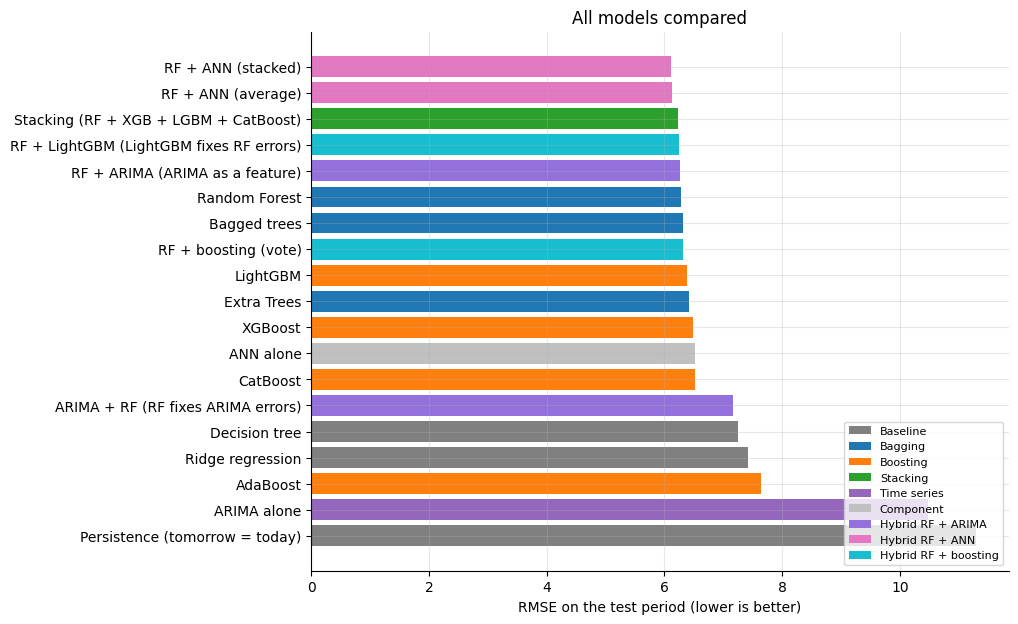

,model,family,RMSE,MAE,R2,train_seconds
0,RF + ANN (stacked),Hybrid RF + ANN,6.109,4.290,0.915,954.7
1,RF + ANN (average),Hybrid RF + ANN,6.138,4.334,0.914,NaN
2,Stacking (RF + XGB + LGBM + CatBoost),Stacking,6.235,4.366,0.911,893.0
3,RF + LightGBM (LightGBM fixes RF errors),Hybrid RF + boosting,6.253,4.346,0.911,NaN
4,RF + ARIMA (ARIMA as a feature),Hybrid RF + ARIMA,6.264,4.393,0.910,NaN
5,Random Forest,Bagging,6.281,4.397,0.910,163.1
6,Bagged trees,Bagging,6.320,4.435,0.909,67.5
7,RF + boosting (vote),Hybrid RF + boosting,6.325,4.422,0.908,NaN
8,LightGBM,Boosting,6.382,4.458,0.907,4.4
9,Extra Trees,Bagging,6.421,4.487,0.906,28.2


In [23]:
final = table()
colors = {'Baseline': 'gray', 'Bagging': 'tab:blue', 'Boosting': 'tab:orange', 'Stacking': 'tab:green',
          'Time series': 'tab:purple', 'Component': 'silver', 'Hybrid RF + ARIMA': 'mediumpurple',
          'Hybrid RF + ANN': 'tab:pink', 'Hybrid RF + boosting': 'tab:cyan'}
f = final.iloc[::-1]
plt.figure(figsize=(9, 7))
plt.barh(f.model, f.RMSE, color=f.family.map(colors))
for fam, c in colors.items():
    plt.barh([f.model.iloc[-1]], [0], color=c, label=fam)
plt.legend(fontsize=8, loc='lower right'); plt.xlabel('RMSE on the test period (lower is better)')
plt.title('All models compared'); plt.show()
final

Best model in each family:

In [24]:
final.groupby('family').first().sort_values('RMSE')[['model', 'RMSE', 'MAE', 'R2']].round(3)

,model,RMSE,MAE,R2
family,,,,
Hybrid RF + ANN,RF + ANN (stacked),6.109,4.290,0.915
Stacking,Stacking (RF + XGB + LGBM + CatBoost),6.235,4.366,0.911
Hybrid RF + boosting,RF + LightGBM (LightGBM fixes RF errors),6.253,4.346,0.911
Hybrid RF + ARIMA,RF + ARIMA (ARIMA as a feature),6.264,4.393,0.910
Bagging,Random Forest,6.281,4.397,0.910
Boosting,LightGBM,6.382,4.458,0.907
Component,ANN alone,6.522,4.672,0.903
Baseline,Decision tree,7.258,5.132,0.879
Time series,ARIMA alone,10.474,7.718,0.749


## 11. What does the model rely on?

**Permutation importance** on the test set: shuffle one feature at a time and see how much worse
Random Forest gets. A big jump means the model depends on that feature.

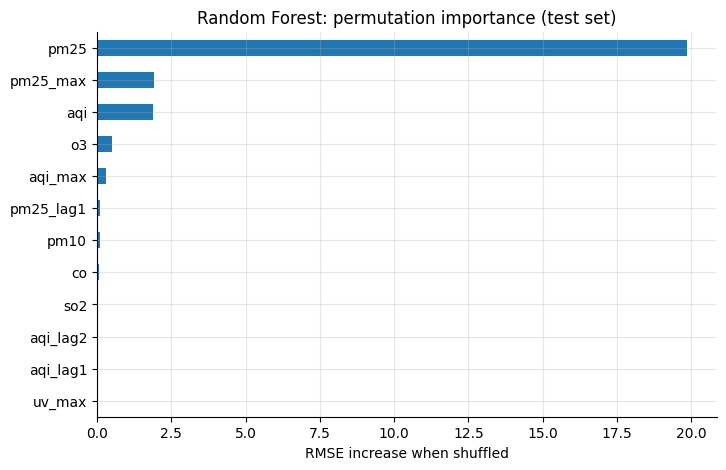

In [25]:
imp = permutation_importance(rf, X_test, y_test, n_repeats=3, random_state=SEED,
                             scoring='neg_root_mean_squared_error', n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
imp.tail(12).plot.barh(color='tab:blue', figsize=(8, 5))
plt.title('Random Forest: permutation importance (test set)'); plt.xlabel('RMSE increase when shuffled'); plt.show()

## 12. Where does the best model go wrong?

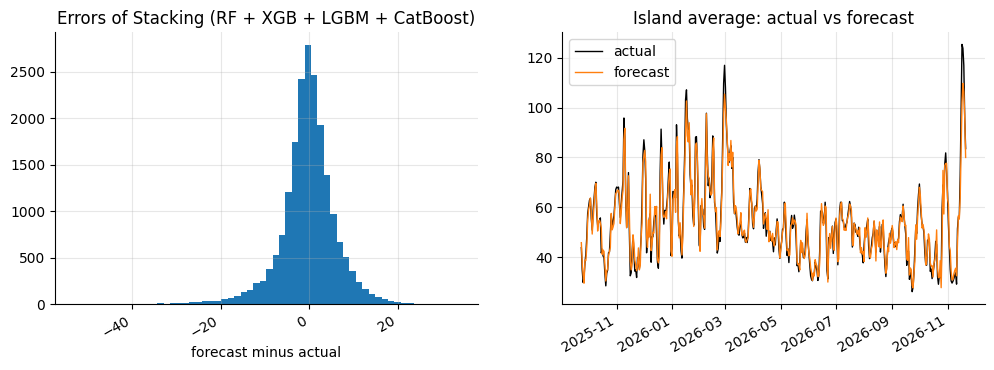

,count,RMSE,mean_error
level,,,
Good,8635,5.27,1.09
Moderate,10569,5.87,-0.57
Unhealthy for sensitive,758,14.58,-10.20
Unhealthy,13,29.35,-26.94


In [26]:
best_ensemble = final[final.family.isin(['Bagging', 'Boosting', 'Stacking'])].iloc[0].model
err = pd.DataFrame({'date': test.date.values, 'actual': y_test.values, 'forecast': predictions[best_ensemble]})
err['error'] = err.forecast - err.actual

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(err.error, bins=60, color='tab:blue'); ax[0].set_title(f'Errors of {best_ensemble}'); ax[0].set_xlabel('forecast minus actual')
d = err.groupby('date')[['actual', 'forecast']].mean()
ax[1].plot(d.actual, lw=1, label='actual', color='black'); ax[1].plot(d.forecast, lw=1, label='forecast', color='tab:orange')
ax[1].set_title('Island average: actual vs forecast'); ax[1].legend(); fig.autofmt_xdate(); plt.show()

err['level'] = pd.cut(err.actual, [0, 50, 100, 150, 500], labels=['Good', 'Moderate', 'Unhealthy for sensitive', 'Unhealthy'])
err.groupby('level', observed=True).error.agg(count='size', RMSE=lambda e: np.sqrt((e ** 2).mean()), mean_error='mean').round(2)

Errors are small on normal days and grow on rare, very polluted days, where the model also tends to under-forecast.

## 13. Forecasting two days ahead

The dataset only contains completed days, so its latest day is *yesterday*. A next-day forecast is
therefore for **today**, and a forecast for **tomorrow** needs two days ahead. Here the best
ensemble is retrained on the two-day target.

In [27]:
from sklearn.base import clone
best_model = {'Random Forest': rf, 'Extra Trees': et, 'Bagged trees': bagging, 'XGBoost': xgb, 'LightGBM': lgbm,
              'CatBoost': cat, 'AdaBoost': ada, 'Stacking (RF + XGB + LGBM + CatBoost)': stack}[best_ensemble]
tr2 = train[train.target2.notna() & (train.date + pd.Timedelta(days=2) < cutoff)]
te2 = test[test.target2.notna()]
pred2 = np.clip(clone(best_model).fit(tr2[FEATURES], tr2.target2).predict(te2[FEATURES]), 0, None)
rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))
pd.DataFrame({
    'forecast': ['1 day ahead (today)', '2 days ahead (tomorrow)'],
    f'{best_ensemble} RMSE': [rmse(y_test, predictions[best_ensemble]), rmse(te2.target2, pred2)],
    'Persistence RMSE': [rmse(y_test, X_test.aqi), rmse(te2.target2, te2.aqi)],
    'R2': [r2_score(y_test, predictions[best_ensemble]), r2_score(te2.target2, pred2)],
}).round(3)

,forecast,Stacking (RF + XGB + LGBM + CatBoost) RMSE,Persistence RMSE,R2
0,1 day ahead (today),6.235,11.287,0.911
1,2 days ahead (tomorrow),14.011,16.942,0.552


## 14. Conclusions
The text below is filled in from the results, so it stays correct if the notebook is re-run on newer data.

In [ ]:
from IPython.display import Markdown
R = final.set_index('model').RMSE
persist = R['Persistence (tomorrow = today)']
best_boost = final[final.family == 'Boosting'].iloc[0].model
rf_boost = compare('Random Forest', best_boost)
best_hybrid = final[final.family.str.startswith('Hybrid')].iloc[0].model
hyb_rf = compare(best_hybrid, 'Random Forest')
top = final.iloc[0]

Markdown(f'''
1. **Ensembles clearly beat the baselines.** The best ensemble, **{best_ensemble}**, has RMSE
   {R[best_ensemble]:.2f}: {1 - R[best_ensemble] / persist:.0%} lower than "tomorrow = today" ({persist:.2f})
   and {1 - R[best_ensemble] / R["Ridge regression"]:.0%} lower than linear regression ({R["Ridge regression"]:.2f}).
2. **Random Forest vs boosting:** RF scores {R["Random Forest"]:.2f}, the best booster ({best_boost})
   {R[best_boost]:.2f}. Bootstrap verdict: *{rf_boost["verdict"]}*. XGBoost, LightGBM, CatBoost and RF are
   all close; AdaBoost is clearly weaker ({R["AdaBoost"]:.2f}).
3. **Stacking** reaches {R["Stacking (RF + XGB + LGBM + CatBoost)"]:.2f}, combining the strengths of RF and the boosters.
4. **Hybrids:** the best is **{best_hybrid}** ({R[best_hybrid]:.2f}); against RF alone: *{hyb_rf["verdict"]}*.
   ARIMA on its own scores {R["ARIMA alone"]:.2f}: it only sees one zone's past AQI, while the tree models also
   see pollutants, season and location.
5. **Best model overall: {top.model}** (RMSE {top.RMSE:.2f}, R² {top.R2:.3f}).
6. **Lesson:** most of the gain comes from moving from one model to an ensemble. After that, the
   choice between good ensembles matters much less than the features (today's AQI and recent history).
''')


1. **Ensembles clearly beat the baselines.** The best ensemble, **Stacking (RF + XGB + LGBM + CatBoost)**, has RMSE
   6.24: 45% lower than "tomorrow = today" (11.29)
   and 16% lower than linear regression (7.42).
2. **Random Forest vs boosting:** RF scores 6.28, the best booster (LightGBM)
   6.38. Bootstrap verdict: *no clear difference*. XGBoost, LightGBM, CatBoost and RF are
   all close; AdaBoost is clearly weaker (7.63).
3. **Stacking** reaches 6.24, combining the strengths of RF and the boosters.
4. **Hybrids:** the best is **RF + ANN (stacked)** (6.11); against RF alone: *RF + ANN (stacked) better*.
   ARIMA on its own scores 10.47: it only sees one zone's past AQI, while the tree models also
   see pollutants, season and location.
5. **Best model overall: RF + ANN (stacked)** (RMSE 6.11, R² 0.915).
6. **Lesson:** most of the gain comes from moving from one model to an ensemble. After that, the
   choice between good ensembles matters much less than the features (today's AQI and recent history).


## 15. Limitations

* **Model data, not measurements:** CAMS estimates air quality on ~45 km squares. The models
  forecast CAMS, and real street-level air can differ.
* **Few truly independent series:** 339 DSDs become a few dozen zones, and nearby zones move
  together. That is why the significance check resamples whole days.
* **One test period:** results come from one split (the last 30% of days). Another period could
  rank close models differently.
* **Fixed settings:** only LightGBM's search is shown; the other settings come from the same kind
  of search, but a bigger search could change close rankings.

## 16. Dashboard

The same models power an interactive Streamlit dashboard (map of all DSDs, forecasts for today and
tomorrow, model comparisons). Run it from the project folder with `streamlit run app.py`.